In [1]:
from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_ceic import load_cpi_series
from src.features.reconstruct_index import add_reconstructed_indices
from src.models.operational_benchmark import (
    forecast_operational_benchmark,
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "china_cpi.csv"

In [2]:
cpi = load_cpi_series(DATA_PATH)
cpi = add_reconstructed_indices(cpi)

cpi.tail()

,headline_yoy_published,headline_mom_published,core_yoy_published,core_mom_published,headline_index_reconstructed,core_index_reconstructed,headline_yoy_reconstructed,core_yoy_reconstructed,headline_yoy_discrepancy,core_yoy_discrepancy
date,,,,,,,,,,
2026-04-01,1.2,0.3,1.2,0.2,177.527703,124.787561,1.298736,1.200351,0.098736,0.000351
2026-05-01,1.2,-0.1,1.1,-0.1,177.350175,124.662774,1.400238,1.099150,0.200238,-0.000850
2026-06-01,1.0,-0.3,1.0,-0.1,176.818125,124.538111,1.197235,0.998051,0.197235,-0.001949
2026-07-01,0.5,-0.1,0.9,0.3,176.641307,124.911725,0.693264,0.897456,0.193264,-0.002544
2026-08-01,0.8,0.4,1.0,0.1,177.347872,125.036637,1.096037,0.998353,0.296037,-0.001647


In [3]:
FORECAST_ORIGIN = pd.Timestamp("2020-12-01")

headline_sample = cpi.loc["2006-01-01":].dropna(
    subset=[
        "headline_mom_published",
        "headline_index_reconstructed",
    ]
)

headline_result = forecast_operational_benchmark(
    monthly_rate=headline_sample["headline_mom_published"],
    index_level=headline_sample["headline_index_reconstructed"],
    forecast_origin=FORECAST_ORIGIN,
    horizon=24,
)

In [4]:
headline_result.forecast

,forecast_origin,target_date,horizon,mom_forecast,index_forecast,yoy_forecast
0,2020-12-01,2021-01-01,1,0.800,171.167791,-0.427537
1,2020-12-01,2021-02-01,2,0.880,172.674067,-0.348511
2,2020-12-01,2021-03-01,3,-0.680,171.499884,0.175971
3,2020-12-01,2021-04-01,4,-0.220,171.122584,0.863354
4,2020-12-01,2021-05-01,5,-0.320,170.574992,1.351402
5,2020-12-01,2021-06-01,6,-0.120,170.370302,1.331112
6,2020-12-01,2021-07-01,7,0.320,170.915487,1.049077
7,2020-12-01,2021-08-01,8,0.460,171.701698,1.109465
8,2020-12-01,2021-09-01,9,0.600,172.731908,1.513095
9,2020-12-01,2021-10-01,10,0.160,173.008279,1.981461


In [5]:
headline_result.audit.query("horizon == 1")

,forecast_origin,target_date,horizon,input_rank,input_date,input_rate,input_type,mom_forecast
0,2020-12-01,2021-01-01,1,1,2016-01-01,0.5,observed,0.8
1,2020-12-01,2021-01-01,1,2,2017-01-01,1.0,observed,0.8
2,2020-12-01,2021-01-01,1,3,2018-01-01,0.6,observed,0.8
3,2020-12-01,2021-01-01,1,4,2019-01-01,0.5,observed,0.8
4,2020-12-01,2021-01-01,1,5,2020-01-01,1.4,observed,0.8


In [6]:
headline_result.audit.query("horizon == 13")

,forecast_origin,target_date,horizon,input_rank,input_date,input_rate,input_type,mom_forecast
60,2020-12-01,2022-01-01,13,1,2017-01-01,1.0,observed,0.86
61,2020-12-01,2022-01-01,13,2,2018-01-01,0.6,observed,0.86
62,2020-12-01,2022-01-01,13,3,2019-01-01,0.5,observed,0.86
63,2020-12-01,2022-01-01,13,4,2020-01-01,1.4,observed,0.86
64,2020-12-01,2022-01-01,13,5,2021-01-01,0.8,forecast,0.86


In [7]:
headline_forecast = headline_result.forecast.copy()

headline_forecast = headline_forecast.merge(
    cpi[["headline_yoy_published"]],
    left_on="target_date",
    right_index=True,
    how="left",
)

headline_forecast["forecast_error"] = (
    headline_forecast["headline_yoy_published"]
    - headline_forecast["yoy_forecast"]
)

headline_forecast

,forecast_origin,target_date,horizon,mom_forecast,index_forecast,yoy_forecast,headline_yoy_published,forecast_error
0,2020-12-01,2021-01-01,1,0.800,171.167791,-0.427537,-0.3,0.127537
1,2020-12-01,2021-02-01,2,0.880,172.674067,-0.348511,-0.2,0.148511
2,2020-12-01,2021-03-01,3,-0.680,171.499884,0.175971,0.4,0.224029
3,2020-12-01,2021-04-01,4,-0.220,171.122584,0.863354,0.9,0.036646
4,2020-12-01,2021-05-01,5,-0.320,170.574992,1.351402,1.3,-0.051402
5,2020-12-01,2021-06-01,6,-0.120,170.370302,1.331112,1.1,-0.231112
6,2020-12-01,2021-07-01,7,0.320,170.915487,1.049077,1.0,-0.049077
7,2020-12-01,2021-08-01,8,0.460,171.701698,1.109465,0.8,-0.309465
8,2020-12-01,2021-09-01,9,0.600,172.731908,1.513095,0.7,-0.813095
9,2020-12-01,2021-10-01,10,0.160,173.008279,1.981461,1.5,-0.481461


<Axes: title={'center': 'Recursive Operational Benchmark Forecast\nMainland China Headline CPI, Origin: December 2020'}, ylabel='Year-on-year inflation (%)'>

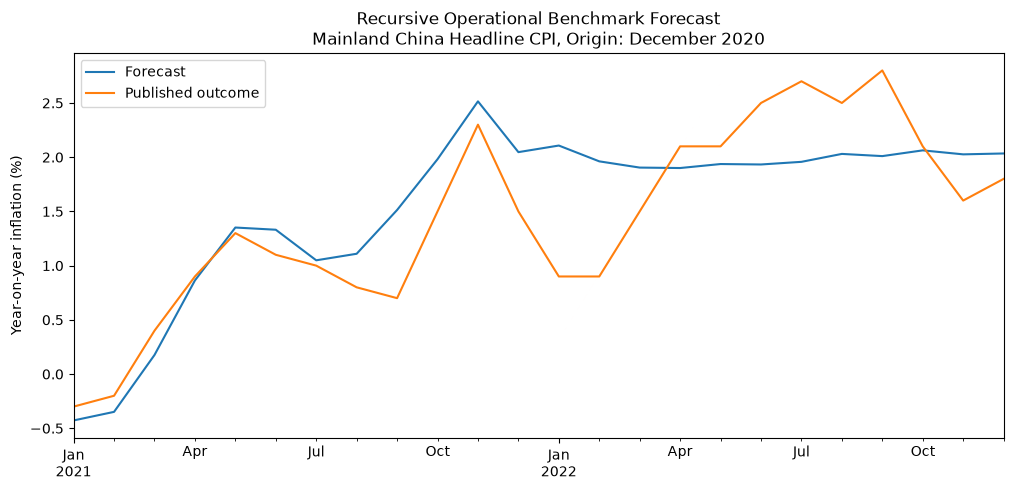

In [8]:
plot_data = headline_forecast.set_index("target_date")[
    [
        "yoy_forecast",
        "headline_yoy_published",
    ]
].rename(
    columns={
        "yoy_forecast": "Forecast",
        "headline_yoy_published": "Published outcome",
    }
)

plot_data.plot(
    title=(
        "Recursive Operational Benchmark Forecast\n"
        "Mainland China Headline CPI, Origin: December 2020"
    ),
    xlabel="",
    ylabel="Year-on-year inflation (%)",
    figsize=(12, 5),
)

In [9]:
headline_forecast[
    [
        "horizon",
        "target_date",
        "yoy_forecast",
        "headline_yoy_published",
        "forecast_error",
    ]
]

,horizon,target_date,yoy_forecast,headline_yoy_published,forecast_error
0,1,2021-01-01,-0.427537,-0.3,0.127537
1,2,2021-02-01,-0.348511,-0.2,0.148511
2,3,2021-03-01,0.175971,0.4,0.224029
3,4,2021-04-01,0.863354,0.9,0.036646
4,5,2021-05-01,1.351402,1.3,-0.051402
5,6,2021-06-01,1.331112,1.1,-0.231112
6,7,2021-07-01,1.049077,1.0,-0.049077
7,8,2021-08-01,1.109465,0.8,-0.309465
8,9,2021-09-01,1.513095,0.7,-0.813095
9,10,2021-10-01,1.981461,1.5,-0.481461


In [10]:
mae = headline_forecast["forecast_error"].abs().mean()

rmse = (
    headline_forecast["forecast_error"]
    .pow(2)
    .mean()
    ** 0.5
)

print(f"MAE:  {mae:.3f} percentage points")
print(f"RMSE: {rmse:.3f} percentage points")

MAE:  0.397 percentage points
RMSE: 0.510 percentage points
